In [ ]:
%matplotlib inline
from matplotlib import pyplot as plt
import numpy as np

In [ ]:
# each point is length, width, type (0, 1)

data = [[3,   1.5, 1],
        [2,   1,   0],
        [4,   1.5, 1],
        [3,   1,   0],
        [3.5, .5,  1],
        [2,   .5,  0],
        [5.5,  1,  1],
        [1,    1,  0]]

data = "All work and no play make Dr. jack a dull boy. It's a beautiful day out there in Jodhpur. Don't you think, it will rain today?"

#mystery_flower = [4.5, 1]
mystery_flower = [5, 3]

In [ ]:
# each point is length, width, type (0, 1)

# Sentence data: [sentence, sentiment_label (0 = negative, 1 = positive)]
data = [
    ["I love this product, it is amazing", 1],
    ["This is the worst experience ever", 0],
    ["Absolutely wonderful and highly recommended", 1],
    ["Terrible service and waste of money", 0],
    ["Really great quality and fast shipping", 1],
    ["Bad quality, do not buy this", 0],
    ["I am very happy with my purchase", 1],
    ["Horrible, completely broken on arrival", 0]
]

mystery_sentence = "This is a fantastic and beautiful item"

#mystery_flower = [4.5, 1]
#mystery_flower = [5, 3]

In [ ]:
#Tokenization
# Import NLTK module in Python
import nltk
# Download NLTK Punkt sentence tokenizer
nltk.download('punkt_tab')
from nltk.tokenize import word_tokenize

# Extract and tokenize each sentence string in the data list
for item in data:
    sentence = item[0]
    words = word_tokenize(sentence)
    print(f"Sentence: {sentence}")
    print(f"Tokens: {words}\n")

Sentence: I love this product, it is amazing
Tokens: ['I', 'love', 'this', 'product', ',', 'it', 'is', 'amazing']

Sentence: This is the worst experience ever
Tokens: ['This', 'is', 'the', 'worst', 'experience', 'ever']

Sentence: Absolutely wonderful and highly recommended
Tokens: ['Absolutely', 'wonderful', 'and', 'highly', 'recommended']

Sentence: Terrible service and waste of money
Tokens: ['Terrible', 'service', 'and', 'waste', 'of', 'money']

Sentence: Really great quality and fast shipping
Tokens: ['Really', 'great', 'quality', 'and', 'fast', 'shipping']

Sentence: Bad quality, do not buy this
Tokens: ['Bad', 'quality', ',', 'do', 'not', 'buy', 'this']

Sentence: I am very happy with my purchase
Tokens: ['I', 'am', 'very', 'happy', 'with', 'my', 'purchase']

Sentence: Horrible, completely broken on arrival
Tokens: ['Horrible', ',', 'completely', 'broken', 'on', 'arrival']



[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [ ]:
# create list of unique words
all_tokens = []
for item in data:
    words = word_tokenize(item[0])
    all_tokens.extend(words)

# lowercase so "This" and "this" count as the same word
all_tokens = [w.lower() for w in all_tokens]

# unique words, sorted so the order is stable
vocab = sorted(set(all_tokens))

print("Vocabulary size:", len(vocab))
print(vocab)

# map each word to an index
word_to_idx = {word: i for i, word in enumerate(vocab)}
print(word_to_idx)


Vocabulary size: 42
[',', 'absolutely', 'am', 'amazing', 'and', 'arrival', 'bad', 'broken', 'buy', 'completely', 'do', 'ever', 'experience', 'fast', 'great', 'happy', 'highly', 'horrible', 'i', 'is', 'it', 'love', 'money', 'my', 'not', 'of', 'on', 'product', 'purchase', 'quality', 'really', 'recommended', 'service', 'shipping', 'terrible', 'the', 'this', 'very', 'waste', 'with', 'wonderful', 'worst']
{',': 0, 'absolutely': 1, 'am': 2, 'amazing': 3, 'and': 4, 'arrival': 5, 'bad': 6, 'broken': 7, 'buy': 8, 'completely': 9, 'do': 10, 'ever': 11, 'experience': 12, 'fast': 13, 'great': 14, 'happy': 15, 'highly': 16, 'horrible': 17, 'i': 18, 'is': 19, 'it': 20, 'love': 21, 'money': 22, 'my': 23, 'not': 24, 'of': 25, 'on': 26, 'product': 27, 'purchase': 28, 'quality': 29, 'really': 30, 'recommended': 31, 'service': 32, 'shipping': 33, 'terrible': 34, 'the': 35, 'this': 36, 'very': 37, 'waste': 38, 'with': 39, 'wonderful': 40, 'worst': 41}


In [ ]:
# creating one-hot encoding
import numpy as np

def one_hot(word):
    vec = np.zeros(len(vocab))
    vec[word_to_idx[word]] = 1
    return vec

# one word
print("love -", one_hot("love"))

# one sentence: a matrix with one row per token
def encode_sentence(sentence):
    tokens = [w.lower() for w in word_tokenize(sentence)]
    return np.array([one_hot(w) for w in tokens])

encoded = encode_sentence(data[0][0])
print(encoded.shape)   # (number of tokens, vocab size)
print(encoded)

love -> [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
(8, 42)
[[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0.
  0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0.
  0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
  0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
  0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
  0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0.
  0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0

In [ ]:
# Step 1: sentence to vector
import numpy as np

def sentence_to_vector(sentence):
    tokens = [w.lower() for w in word_tokenize(sentence)]
    vec = np.zeros(len(vocab))
    for t in tokens:
        if t in word_to_idx:          # ignore words not in the vocabulary
            vec[word_to_idx[t]] += 1
    return vec

In [ ]:
#step 2
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

w = np.random.randn(len(vocab)) * 0.01   # 42 weights, small random start
b = 0.0

def NN(sentence):
    x = sentence_to_vector(sentence)
    return sigmoid(np.dot(w, x) + b)

In [ ]:
#Step 3
alpha = 0.1   # learning rate

for epoch in range(200):
    for sentence, label in data:
        x = sentence_to_vector(sentence)
        pred = sigmoid(np.dot(w, x) + b)
        error = pred - label
        w -= alpha * error * x     # one slope per word weight
        b -= alpha * error

In [ ]:
#Step 4
for sentence, label in data:
    p = NN(sentence)
    print(f"{p:.2f}  (true {label})  {sentence}")

print(NN("I love this great product"))
print(NN("Terrible and broken"))

# Finding the word
for i in np.argsort(w):
    print(vocab[i], round(w[i], 2))

0.99  (true 1)  I love this product, it is amazing
0.01  (true 0)  This is the worst experience ever
0.99  (true 1)  Absolutely wonderful and highly recommended
0.01  (true 0)  Terrible service and waste of money
0.99  (true 1)  Really great quality and fast shipping
0.01  (true 0)  Bad quality, do not buy this
0.99  (true 1)  I am very happy with my purchase
0.01  (true 0)  Horrible, completely broken on arrival
0.9778931173767725
0.24935872953774924
of -1.04
money -1.04
terrible -1.04
waste -1.04
service -1.03
ever -0.96
experience -0.95
the -0.94
worst -0.93
buy -0.84
do -0.84
bad -0.84
not -0.83
horrible -0.82
broken -0.82
arrival -0.81
on -0.81
completely -0.8
this -0.74
, -0.59
is 0.08
quality 0.09
happy 0.58
purchase 0.59
am 0.6
my 0.61
with 0.62
very 0.62
and 0.85
shipping 0.91
really 0.93
recommended 0.93
great 0.93
highly 0.95
absolutely 0.95
fast 0.95
wonderful 0.95
amazing 1.02
love 1.03
product 1.04
it 1.06
i 1.64


IndexError: list index out of range

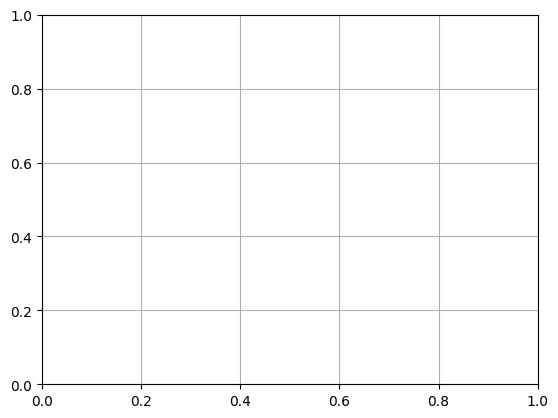

In [ ]:
# scatter plot them
def vis_data():
    plt.grid()

    for i in range(len(data)):
        c = 'r'
        if data[i][2] == 0:
            c = 'b'
        plt.scatter([data[i][0]], [data[i][1]], c=c)

    plt.scatter([mystery_flower[0]], [mystery_flower[1]], c='gray')

vis_data()

In [ ]:
# network

#       o  flower type
#      / \  w1, w2, b
#     o   o  length, width

In [ ]:
# activation function

def sigmoid(x):
    return 1/(1+np.exp(-x))

def sigmoid_p(x):
    return sigmoid(x) * (1-sigmoid(x))

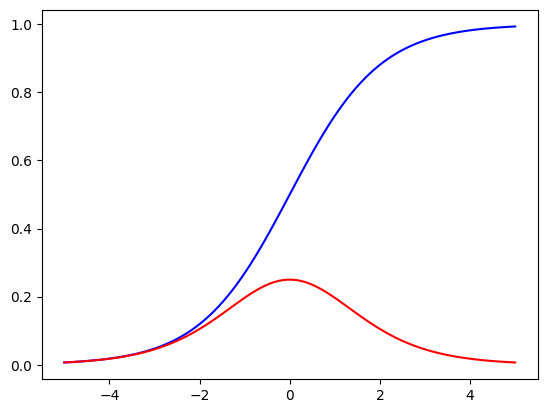

In [ ]:
X = np.linspace(-5, 5, 100)
plt.figure()
plt.plot(X, sigmoid(X), c="b") # sigmoid in blue
fig = plt.plot(X, sigmoid_p(X), c="r") # sigmoid_p in red
plt.show()

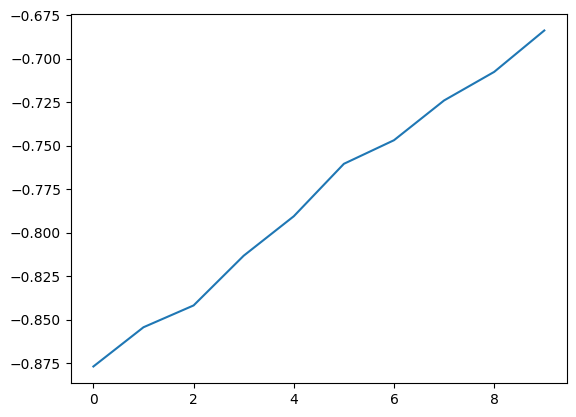

In [ ]:
# train

def train():
    #random init of weights
    w1 = np.random.randn()
    w2 = np.random.randn()
    b = np.random.randn()

    #iterations = 10000
    iterations = 1000
    learning_rate = 0.0001
    costs = [] # keep costs during training, see if they go down

    for i in range(iterations):
        # get a random point
        ri = np.random.randint(len(data))
        point = data[ri]

        z = point[0] * w1 + point[1] * w2 + b
        pred = sigmoid(z) # networks prediction

        target = point[2]

        # cost for current random point
        #cost = np.square(pred - target)
        cost = (pred - target)

        # print the cost over all data points every 1k iters
        if i % 100 == 0:
            c = 0
            for j in range(len(data)):
                p = data[j]
                p_pred = sigmoid(w1 * p[0] + w2 * p[1] + b)
                #c += np.square(p_pred - p[2])
                c += (p_pred - p[2])
            costs.append(c)

        dcost_dpred = 2 * (pred - target)
        dpred_dz = sigmoid_p(z)

        dz_dw1 = point[0]
        dz_dw2 = point[1]
        dz_db = 1

        dcost_dz = dcost_dpred * dpred_dz

        dcost_dw1 = dcost_dz * dz_dw1
        dcost_dw2 = dcost_dz * dz_dw2
        dcost_db = dcost_dz * dz_db

        w1 = w1 - learning_rate * dcost_dw1
        w2 = w2 - learning_rate * dcost_dw2
        b = b - learning_rate * dcost_db

    return costs, w1, w2, b

costs, w1, w2, b = train()

fig = plt.plot(costs)

In [ ]:
# predict what the myster flower is!

z = w1 * mystery_flower[0] + w2 * mystery_flower[1] + b
pred = sigmoid(z)

print(pred)
print("close to 0 -> blue, close to 1 -> red")

0.9485089413550509
close to 0 -> blue, close to 1 -> red


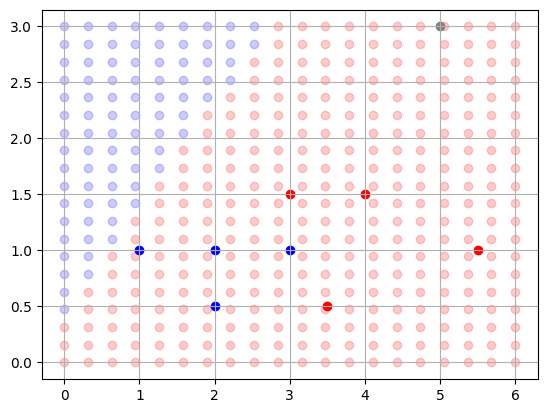

In [ ]:
# check out the networks predictions in the x,y plane
for x in np.linspace(0, 6, 20):
    for y in np.linspace(0, 3, 20):
        pred = sigmoid(w1 * x + w2 * y + b)
        c = 'b'
        if pred > .5:
            c = 'r'
        plt.scatter([x],[y],c=c, alpha=.2)

# plot points over network predictions
# you should see a split, with half the predictions blue
# and the other half red.. nicely predicting each data point!
vis_data()